In [1]:
# Enable auto-reloading so edits to .py files update without restarting the kernel
%load_ext autoreload
%autoreload 2

import numpy as np
import complex_network_dynamics as cnd
import matplotlib.pyplot as plt
import pandas as pd 
import time

In [2]:
# help(cnd)

<div><h3 style = "text-align:center">Simulation of Uncoupled Model of Lorenz with Euler and RK4 </h3></div>

In [3]:
# Integration settings
y0 = np.array([1.0, 1.0, 1.0], dtype=float).ravel()
h = 0.0001  # Small step size required by explicit Euler
n_steps = int(2e6)  # Total tracking time = {n_steps*h = } secs
n_transient = int(2e4)
t0_Euler = time.perf_counter()

# 3. Run simulation
t_vals_Lorenz_Euler, traj_Lorenz_Euler, spectrum_Lorenz_Euler = cnd.euler_with_lyapunov(
    f=cnd.lorenz,
    df=cnd.lorenz_jacobian,
    y0=y0,
    t0=0.0,
    h=h,
    n_steps=n_steps,
    n_transient=n_transient,
    qr_interval=5,
    sigma=10.0,
    rho=28.0,
    beta=8.0/3.0
)

t1_Euler = time.perf_counter()

Computed Lyapunov Spectrum: λ1 = 0.852, λ2 = 0.012, λ3 = -14.534
Actual Lyapunov Spectrum:   λ1 = 0.906, λ2 = 0.000, λ3 = -14.572


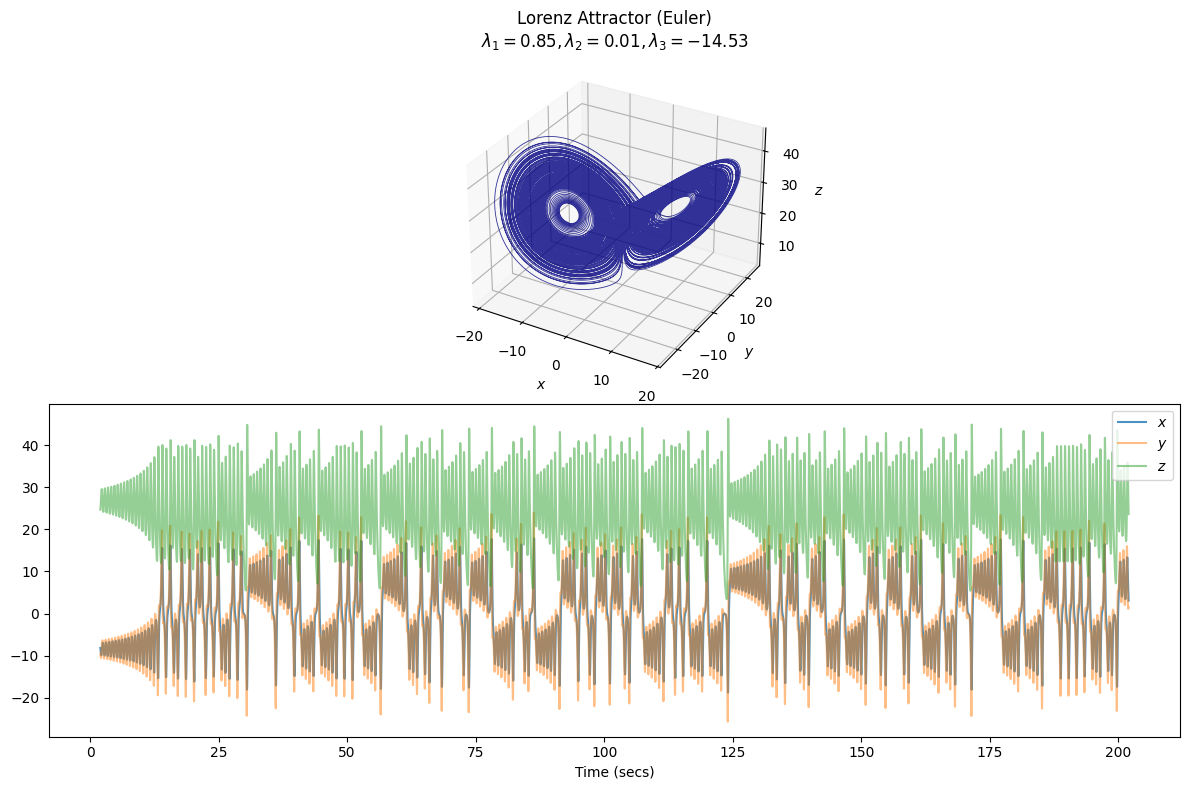

In [4]:

import matplotlib.pyplot as plt

print(f"Computed Lyapunov Spectrum: λ1 = {spectrum_Lorenz_Euler[0]:.3f}, λ2 = {spectrum_Lorenz_Euler[1]:.3f}, λ3 = {spectrum_Lorenz_Euler[2]:.3f}\n"
    f"Actual Lyapunov Spectrum:   λ1 = {0.9056:.3f}, λ2 = {0.0:.3f}, λ3 = {-14.5723:.3f}")

# 4. Plot 3D Trajectory
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(2,1,1, projection="3d")
ax.plot(traj_Lorenz_Euler[:, 0], traj_Lorenz_Euler[:, 1], traj_Lorenz_Euler[:, 2], color="navy", lw=0.6, alpha=0.8)
ax.set_title(
    f"Lorenz Attractor (Euler)\n$\\lambda_1={spectrum_Lorenz_Euler[0]:.2f}, \\lambda_2={spectrum_Lorenz_Euler[1]:.2f}, \\lambda_3={spectrum_Lorenz_Euler[2]:.2f}$"
)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")

ax2 = fig.add_subplot(2,1,2)
ax2.plot(t_vals_Lorenz_Euler,traj_Lorenz_Euler[:,0],alpha = 0.8, label= '$x$')
ax2.plot(t_vals_Lorenz_Euler,traj_Lorenz_Euler[:,1], alpha=0.5, label ='$y$')
ax2.plot(t_vals_Lorenz_Euler,traj_Lorenz_Euler[:,2], alpha = 0.5, label = '$z$')
ax2.legend(loc= 'upper right')
ax2.set_xlabel("Time (secs)")
plt.tight_layout()
plt.show()

In [5]:
# Integration settings
y0 = [1.0, 1.0, 1.0]
h = 0.05  
n_steps = int(2e6)  # Total tracking time = n_steps*h
n_transient = int(2e4)

t0_RK4 = time.perf_counter()

t_vals_Lorenz_RK4, traj_Lorenz_RK4, lyap_spectrum_Lorenz_RK4 = cnd.integrators.rk4_with_lyapunov(
    f = cnd.lorenz,
    y0=y0,
    t0=0.0,
    h=h,
    n_steps = n_steps,
    df=cnd.lorenz_jacobian,
    lyap_mode='spectrum',
    n_transient=n_transient,
    qr_interval=5,
    sigma=10.0,
    rho=28.0,
    beta=8.0/3.0)
t1_RK4 = time.perf_counter()


In [6]:
print(f"Actual Lyapunov Spectrum:   λ1 = {0.9056:.4f}, λ2 = {0.0:.4f}, λ3 = {-14.5723:.4f}\n"
      f"RK4 Lyapunov Spectrum of Lorenz:  λ1 = {lyap_spectrum_Lorenz_RK4[0]:.4f}, λ2 = {lyap_spectrum_Lorenz_RK4[1]:.4f}, λ3 = {lyap_spectrum_Lorenz_RK4[2]:.4f}\n"
     f"Elapsed time for RK4: {t1_RK4 - t0_RK4:.6f} seconds \n"
     f"Euler Lyapunov Spectrum of Lorenz: λ1 = {spectrum_Lorenz_Euler[0]:.4f}, λ2 = {spectrum_Lorenz_Euler[1]:.4f}, λ3 = {spectrum_Lorenz_Euler[2]:.4f}\n"
     f"Elapsed time for Euler: {t1_Euler - t0_Euler:.6f} seconds")

Actual Lyapunov Spectrum:   λ1 = 0.9056, λ2 = 0.0000, λ3 = -14.5723
RK4 Lyapunov Spectrum of Lorenz:  λ1 = 0.9043, λ2 = -0.0000, λ3 = -14.4715
Elapsed time for RK4: 55.772309 seconds 
Euler Lyapunov Spectrum of Lorenz: λ1 = 0.8519, λ2 = 0.0119, λ3 = -14.5338
Elapsed time for Euler: 15.343267 seconds



<div> <h2 style = "text-align: center">Integration of <strong>Coupled Lorenz Model</strong> using the methods of Euler, RK4 and RK45 </h2>

Here, we solve the differential equations of Lorenz model in $N \times 3 $ dimensions using the integration methods, Euler, RK4 and RK5 for the compatible parameters and measure their running time to compare them at the end. Here, $N$ is the number of nodes in network and we used 12 nodes network from the library "<strong>C</strong>omplex <strong>N</strong>etwork <strong>D</strong>ynamics" for all.

<h4>Calling Adjacency Matrices from the package content: </h4>
</div>



</div>


(12, 12)


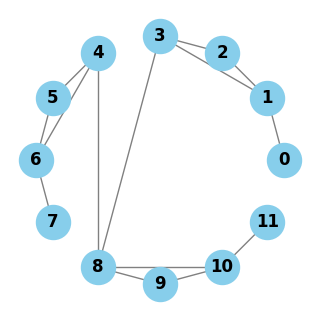

In [7]:
import networkx as nx

# Load the matrix directly
adj_12nodes = cnd.load_network("12nodes")
print(adj_12nodes.shape)
G = nx.from_numpy_array(adj_12nodes)
# Visualize the graph
plt.figure(figsize=(3, 3))
pos = nx.circular_layout(G)

nx.draw(
    G, 
    pos, 
    with_labels=True, 
    node_color="skyblue", 
    node_size=600, 
    edge_color="gray", 
    font_weight="bold"
)
# plt.title(f"Random {d}-Regular Graph with {n} Nodes")
plt.show()

<h3> Using Euler Method </h3>

To solve the differential equations using Euler method, we require small step size like $h=0.0001 = 10^{-4}$ or smaller maybe to get more precise results. 

We simulate the model for 250 secs and remove first 50 secs (20% of all) as transient. 

In [8]:
## Initial Values for coupled Lorenz
records = []

n_nodes = adj_12nodes.shape[0]
rng = np.random.default_rng(seed=2)
xi = rng.uniform(-1.0, 1.0, size=n_nodes)
# Compute coordinate values
x0 = 0.10 + 0.5 * xi
y0 = -0.19 + 0.5 * xi
z0 = -0.27 + 0.5 * xi
xyz0 = np.concatenate([x0, y0, z0])
xyz0.shape
h_euler = 1e-4  # Small step size for Euler
n_steps_euler = int(25e5)  # total integration time is h * n_steps = 250 secs.
n_transient_euler = int(5e5) # removing the first 50 secs as transient



In [9]:
# Run simulation
t0_coupledLorenz_Euler = time.perf_counter()

t_vals_Coupled_Lorenz_Euler, traj_Coupled_Lorenz_Euler, spectrum_Coupled_Lorenz_Euler = cnd.euler_with_lyapunov(
    f=cnd.coupled_lorenz,
    df=cnd.coupled_lorenz_jacobian,
    y0=xyz0,
    t0=0.0,
    h=h_euler,
    n_steps=n_steps_euler,
    n_transient=n_transient_euler,
    qr_interval=5,
    A = adj_12nodes, 
    sigma=10.0,
    rho=28.0,
    beta=8.0/3.0
)
t1_coupledLorenz_Euler = time.perf_counter()
elapsed_time_Euler = t1_coupledLorenz_Euler - t0_coupledLorenz_Euler

records.append({
    "Method": "Forward Euler",
    "Type": "Fixed-step (Order 1)",
    "Step Size / Tol": f"h = {h_euler}",
    "Total Steps / Evals": n_steps_euler,
    "Runtime (s)": round(elapsed_time_Euler, 3),
    "Max Lyapunov (λ₁)": round(spectrum_Coupled_Lorenz_Euler[0], 5),
    "Neutral Exponent (λ₀)": round(min(spectrum_Coupled_Lorenz_Euler, key=lambda x: abs(x)), 5),
})


print( f"Elapsed time for Euler: {elapsed_time_Euler:.6f} seconds")

Elapsed time for Euler: 94.111304 seconds


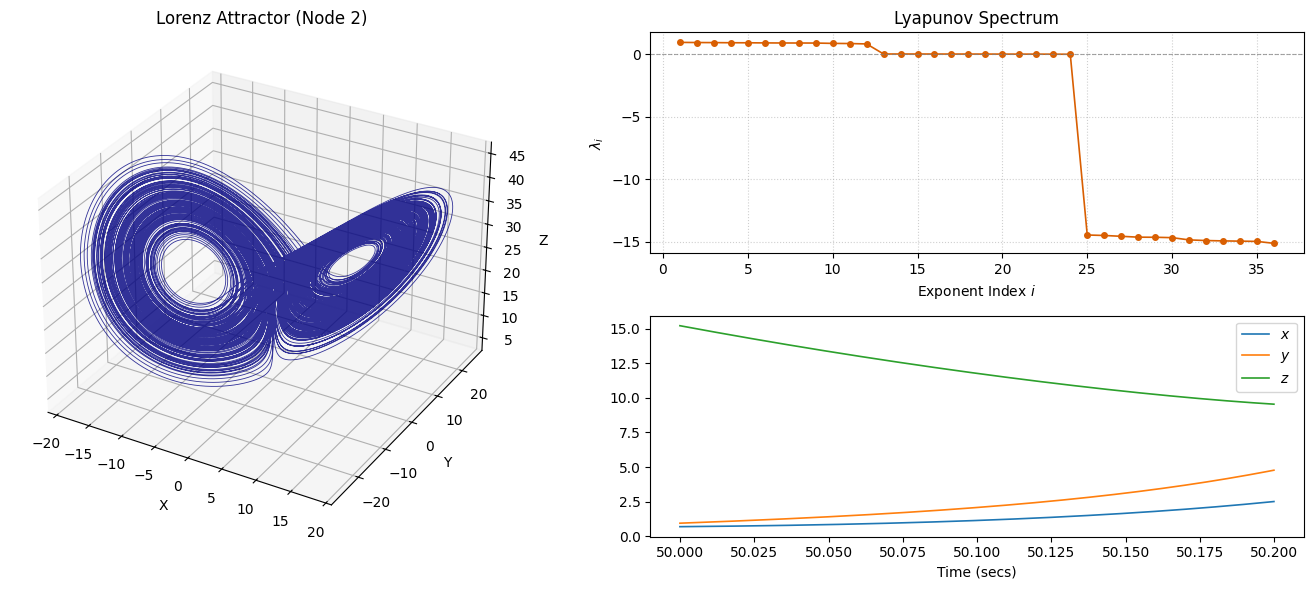

In [10]:

# 1. Expand width (e.g. 14x6) so two plots have room side-by-side
node_idx = 1
time_span = int(100) # to view 10 secs
view_steps = int(time_span/h)

fig = plt.figure(figsize=(14, 6))

# 2. Left Subplot (1 row, 2 columns, index 1) with 3D projection
ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    traj_Coupled_Lorenz_Euler[:, node_idx],
    traj_Coupled_Lorenz_Euler[:, n_nodes + node_idx],
    traj_Coupled_Lorenz_Euler[:, 2 * n_nodes + node_idx],
    color="navy",
    lw=0.6,
    alpha=0.8,
)
ax1.set_title(f"Lorenz Attractor (Node {node_idx + 1})")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# 3. Right Subplot (1 row, 2 columns, index 2) - standard 2D
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(
    range(1, len(spectrum_Coupled_Lorenz_Euler) + 1),
    spectrum_Coupled_Lorenz_Euler,
    "o-",
    color="#d95f02",
    markersize=4,
    lw=1.2,
)
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)  # Zero reference line
ax2.set_title("Lyapunov Spectrum")
ax2.set_xlabel("Exponent Index $i$")
ax2.set_ylabel(r"$\lambda_i$")
ax2.grid(True, linestyle=":", alpha=0.6)


# 3. Right Subplot (1 row, 2 columns, index 2) - standard 2D
ax3 = fig.add_subplot(2, 2, 4)
ax3.plot(t_vals_Coupled_Lorenz_Euler[:view_steps], traj_Coupled_Lorenz_Euler[:view_steps,[node_idx]], 
         markersize=4, lw=1.2, label = "$x$")
ax3.plot(t_vals_Coupled_Lorenz_Euler[:view_steps], traj_Coupled_Lorenz_Euler[:view_steps,[node_idx+n_nodes]], 
         markersize=4, lw=1.2, label = "$y$")
ax3.plot(t_vals_Coupled_Lorenz_Euler[:view_steps], traj_Coupled_Lorenz_Euler[:view_steps,[node_idx+2*n_nodes]], 
         markersize=4, lw=1.2, label = "$z$")


ax3.set_xlabel("Time (secs)")
ax3.legend()

plt.tight_layout()
plt.show()

<h3> Using RK4 Method </h3>

In [11]:

h_rk4 = 1e-3  # Small step size for Euler
n_steps_rk4 = int(25e4)  # total integration time is h * n_steps = 250 secs.
n_transient_rk4 = int(5e4) # removing the first 50 secs as transient

t0_RK4 = time.perf_counter()
t_vals_coupledLorenz_RK4, traj_coupledLorenz_RK4, lyap_coupledspectrum_Lorenz_RK4 = cnd.integrators.rk4_with_lyapunov(
    f = cnd.coupled_lorenz,
    df=cnd.coupled_lorenz_jacobian,
    y0=xyz0,
    t0=0.0,
    h=h_rk4,
    n_steps = n_steps_rk4,
    lyap_mode='spectrum',
    n_transient=n_transient_rk4,
    qr_interval=5,
    A=adj_12nodes,
    K=0.1,
    sigma=10.0,
    rho=28.0,
    beta=8.0/3.0)

t1_RK4 = time.perf_counter()

time_elapsed_RK4 = t1_RK4 - t0_RK4

records.append({
    "Method": "Runge-Kutta 4 (RK4)",
    "Type": "Fixed-step (Order 4)",
    "Step Size / Tol": f"h = {h_rk4}",
    "Total Steps / Evals": n_steps_rk4,
    "Runtime (s)": round(time_elapsed_RK4, 3),
    "Max Lyapunov (λ₁)": round(lyap_coupledspectrum_Lorenz_RK4[0], 5),
    "Neutral Exponent (λ₀)": round(min(lyap_coupledspectrum_Lorenz_RK4, key=lambda x: abs(x)), 5)
})


### Using RK4 in njit (Fast RK4)

In [12]:
t0_RK4_fast = time.perf_counter()
# Create the args tuple (A, K, sigma, rho, beta)
system_args = (adj_12nodes, 0.1, 10.0, 28.0, 8.0/3.0) 

# Build the solver
lorenz_solver = cnd.integrators.build_rk4_lyapunov(
    f=cnd.continuous_models.coupled_lorenz_njit, 
    df=cnd.continuous_models.coupled_lorenz_jacobian_njit)

# Run the simulation
t_vals, traj, final_spectrum, lyap_times, lyap_history = lorenz_solver(
    y0=xyz0,
    t0=0.0,
    h=h_rk4,
    n_steps=n_steps_rk4,
    qr_interval=5,
    args=system_args,  # Pass the tuple here!
    n_transient=n_transient_rk4,
    save_history=True
)
t1_RK4_fast = time.perf_counter()

time_elapsed_RK4_fast = t1_RK4_fast - t0_RK4_fast

records.append({
    "Method": "Fast RK4",
    "Type": "Fixed-step (Order 4)",
    "Step Size / Tol": f"h = {h_rk4}",
    "Total Steps / Evals": n_steps_rk4,
    "Runtime (s)": round(time_elapsed_RK4_fast, 3),
    "Max Lyapunov (λ₁)": round(final_spectrum[0], 5),
    "Neutral Exponent (λ₀)": round(min(final_spectrum, key=lambda x: abs(x)), 5),
})


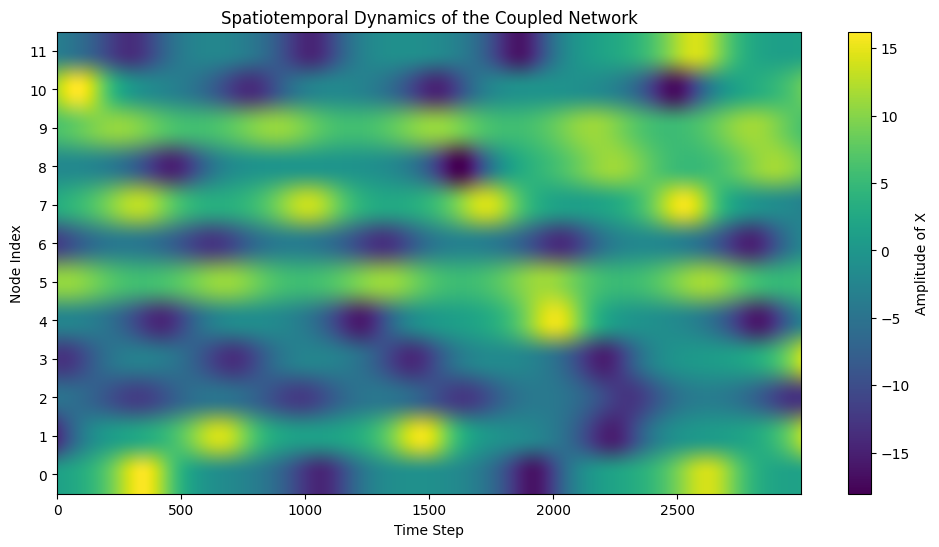

In [49]:
import matplotlib.pyplot as plt

# Extract just the x-coordinates for all 12 nodes (assuming they are columns 0 to 11)
x_data = traj[:, 0:12]

plt.figure(figsize=(12, 6))
# Plot a slice of time (e.g., the last 3000 steps) to see the detail
plt.imshow(x_data[-3000:].T, aspect='auto', cmap='viridis', origin='lower')

plt.colorbar(label='Amplitude of X')
plt.xlabel('Time Step')
plt.ylabel('Node Index')
plt.title('Spatiotemporal Dynamics of the Coupled Network')
plt.yticks(range(12))
plt.show()


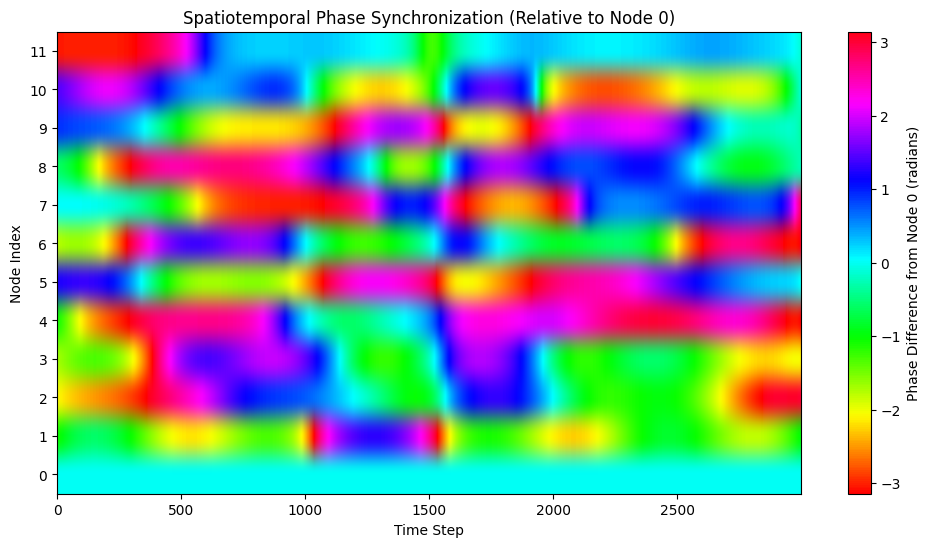

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# 1. Extract the x-coordinates for all 12 nodes
x_data = traj[:, 0:12]

# 2. Extract instantaneous phase using the Hilbert Transform
# Apply along the time axis (axis=0) to get the analytic signal
analytic_signal = hilbert(x_data, axis=0)
instantaneous_phases = np.angle(analytic_signal) # Returns phases in [-pi, pi]

# 3. Calculate Phase Synchronization (Relative to Node 0)
# Extract Node 0's phase and broadcast it to subtract from all other nodes
reference_phase = instantaneous_phases[:, 0][:, np.newaxis]
phase_diff = instantaneous_phases - reference_phase

# Wrap the phase differences back to the [-pi, pi] interval for clean plotting
phase_diff_wrapped = (phase_diff + np.pi) % (2 * np.pi) - np.pi

# 4. Plot the Phase Difference Heatmap
plt.figure(figsize=(12, 6))

# Zoom in on a specific time window to see the details clearly
window_size = 3000
plt.imshow(phase_diff_wrapped[-window_size:].T, 
           aspect='auto', 
           cmap='hsv',  # 'hsv' is cyclic, meaning -pi (red) and +pi (red) match smoothly
           origin='lower')

plt.colorbar(label='Phase Difference from Node 0 (radians)')
plt.xlabel('Time Step')
plt.ylabel('Node Index')
plt.title('Spatiotemporal Phase Synchronization (Relative to Node 0)')
plt.yticks(range(12))
plt.show()



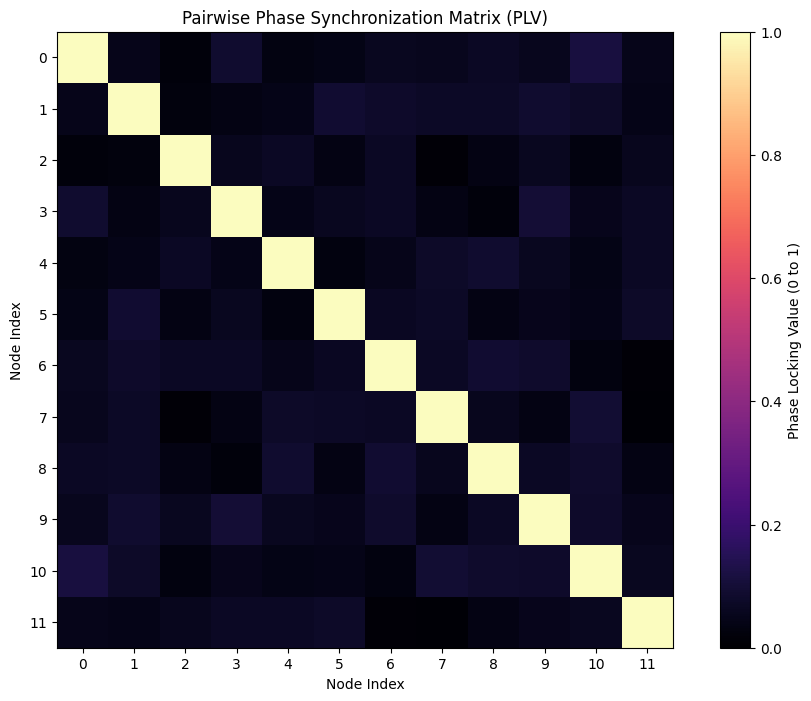

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# Assume 'instantaneous_phases' is your (T, N) array from the Hilbert transform
T, N = instantaneous_phases.shape

# 1. Map the real-valued phases onto the complex unit circle
complex_phases = np.exp(1j * instantaneous_phases)

# 2. Compute the N x N PLV matrix using conjugate matrix multiplication
# The '@' operator triggers highly optimized BLAS/LAPACK C-libraries under the hood
plv_matrix = np.abs(complex_phases.T @ np.conj(complex_phases)) / T

# 3. Visualize the resulting N x N synchronization matrix
plt.figure(figsize=(12, 8))
plt.imshow(plv_matrix, cmap='', vmin=0, vmax=1, origin='upper')

plt.colorbar(label='Phase Locking Value (0 to 1)')
plt.title('Pairwise Phase Synchronization Matrix (PLV)')
plt.xlabel('Node Index')
plt.ylabel('Node Index')
plt.xticks(range(N))
plt.yticks(range(N))
plt.show()


In [56]:
import pandas as pd
print(pd.DataFrame(plv_matrix))

          0         1         2         3         4         5         6   \
0   1.000000  0.047948  0.021572  0.087670  0.035060  0.041314  0.061830   
1   0.047948  1.000000  0.026996  0.038301  0.046135  0.093409  0.078363   
2   0.021572  0.026996  1.000000  0.057561  0.069410  0.035510  0.068346   
3   0.087670  0.038301  0.057561  1.000000  0.044503  0.061290  0.069083   
4   0.035060  0.046135  0.069410  0.044503  1.000000  0.028679  0.048986   
5   0.041314  0.093409  0.035510  0.061290  0.028679  1.000000  0.062766   
6   0.061830  0.078363  0.068346  0.069083  0.048986  0.062766  1.000000   
7   0.058434  0.073391  0.012358  0.036391  0.077272  0.073022  0.067963   
8   0.067952  0.071869  0.036165  0.021982  0.086077  0.036044  0.093537   
9   0.057784  0.086984  0.061376  0.098025  0.060395  0.052725  0.082767   
10  0.113812  0.074358  0.028208  0.052964  0.039265  0.043829  0.028255   
11  0.050719  0.046695  0.057977  0.067129  0.069369  0.077792  0.014954   

          7

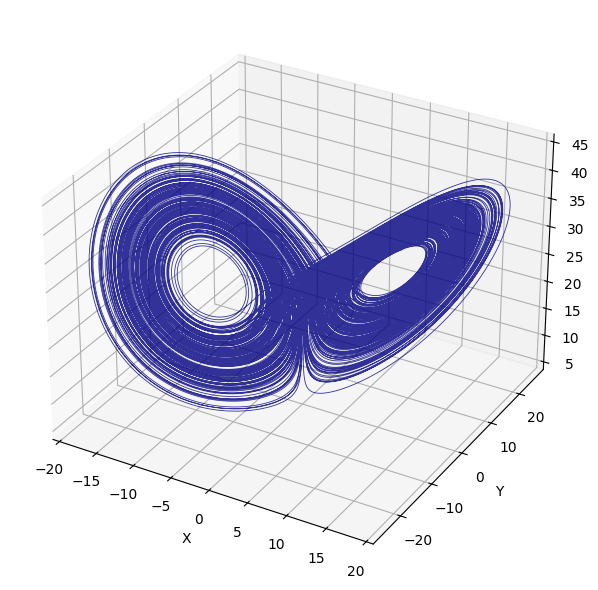

In [14]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(traj_coupledLorenz_RK4[:, 0+5], traj_coupledLorenz_RK4[:, n_nodes+5], traj_coupledLorenz_RK4[:, 2*n_nodes+5], color="navy", lw=0.6, alpha=0.8)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()

<h3> Using RK45 Adaptive Method </h3>

In [15]:
h_rk45 = 1e-3  # Small step size for Euler
t_total = 250.0 
n_transient_rk45 = int(5e4) # removing the first 50 secs as transient

print(f"Integrating Lorenz system for t = {t_total} with step size = {h_rk45}...")
t_start_rk45 = time.perf_counter()

t_vals, traj, lyap_spec = cnd.integrators.solve_ivp_with_lyapunov(
    f=cnd.coupled_lorenz,
    df=cnd.coupled_lorenz_jacobian,
    y0=xyz0,
    t_total=t_total,
    dt_qr=h_rk45,
    method="RK45",
    lyap_mode="spectrum",
    n_transient_steps=n_transient_rk45,
    A = adj_12nodes,
    K=0.1,sigma=10.0,
    rho=28.0,
    beta=8/3)
t_end_rk45 = time.perf_counter()
elapsed_time_rk45 = t_end_rk45 - t_start_rk45
print(f"Completed in {elapsed_time_rk45:.2f} seconds.\n")

records.append({
    "Method": "Dormand-Prince (RK45)",
    "Type": "Adaptive-step (Order 5)",
    "Tolerance": f"rtol={1e-07:.0e}, atol={1e-09:.0e}",
    "Step Size / Tol": f"step_size = {h_rk45}",
    "Total Steps / Evals": f"{int(t_total / h_rk45)} QR windows (adaptive)",
    "Runtime (s)": round(elapsed_time_rk45, 3),
    "Max Lyapunov (λ₁)": round(lyap_spec[0], 5),
    "Neutral Exponent (λ₀)": round(min(lyap_spec, key=lambda x: abs(x)), 5)
})


Integrating Lorenz system for t = 250.0 with step size = 0.001...
Completed in 135.19 seconds.



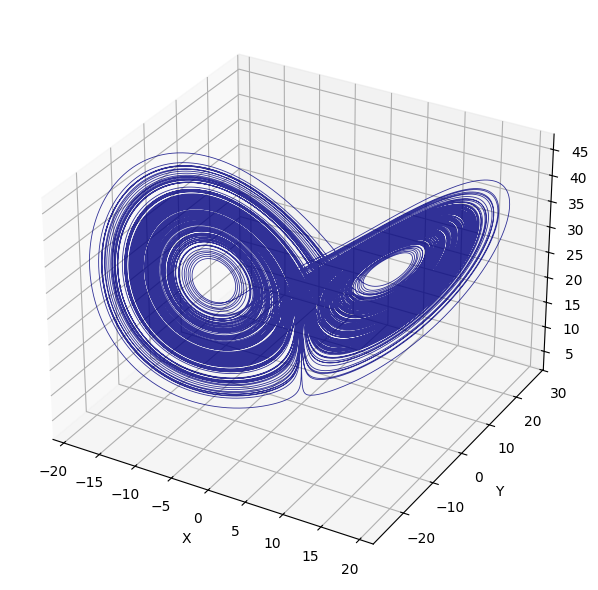

In [16]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(traj[:, 0+5], traj[:, n_nodes+5], traj[:, 2*n_nodes+5], color="navy", lw=0.6, alpha=0.8)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()

<div><h3 style = 'text-align:center'> Comparison of the Methods on Coupled Model </h3></div>

In [17]:
import pandas as pd 

df_comparison = pd.DataFrame(records)
df_comparison

,Method,Type,Step Size / Tol,Total Steps / Evals,Runtime (s),Max Lyapunov (λ₁),Neutral Exponent (λ₀),Tolerance
0,Forward Euler,Fixed-step (Order 1),h = 0.0001,2500000,94.111,0.93296,-0.00096,NaN
1,Runge-Kutta 4 (RK4),Fixed-step (Order 4),h = 0.001,250000,34.659,0.92859,-0.00083,NaN
2,Fast RK4,Fixed-step (Order 4),h = 0.001,250000,12.837,0.92858,-0.00082,NaN
3,Dormand-Prince (RK45),Adaptive-step (Order 5),step_size = 0.001,250000 QR windows (adaptive),135.185,0.94660,-0.00069,"rtol=1e-07, atol=1e-09"
